In [2]:
# ============================================================
# Notebook setup
# ============================================================

%load_ext autoreload
%autoreload 2

# Control figure size
figsize=(14, 4.5)

from util import util
import numpy as np
import os
from sklearn.metrics import accuracy_score
import pandas as pd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Constrained ML via Inference-Time Projection

## From Constraints at Inference Time...

**Let's consider again our constrained training approach**

Formally, it amounted to solving:

$$
\mathop{\rm arg\,min}_{\theta} \left\{ L(\hat{y}, y) \mid g(\hat{y}) \leq 0 \right\} \quad \text{ with: } \hat{y} = f(x; \theta)
$$

...Which we did by relying on a dual ascent method

**In general, this a _versatile_ approach**

* Penalty terms are (often) not hard to define
* The whole solution framework is close to classical gradient descent
* The constraints can be defined over multiple examples (e.g. fairness)

## ...To Inference-Time Projection

**...But what if we enforced constraints _at inference time_?**

We could start by trainingn a model as usual:

$$
\theta^* = \mathop{\rm arg\,min}_{\theta} \{ L(\hat{y}, y) \}  \quad \text{ with: } \hat{y} = f(x; \theta)
$$

...And then _correcting the predictions_:

$$
\hat{z} = \mathop{\rm argmin}_{z} \{ L(z, \hat{y}) \mid g(z) \leq 0, \} \quad \text{ with: } \hat{y} = f(x; \theta^*)
$$

**This process is often understood as a form of projection**

* Since the correction moves the predictions within the feasible space
* We'll call this approach _inference-time projection_

## Projection vs MAP

**When $L$ represents a likelihood**

...We can see the projection process process as MAP computation:

$$
\hat{z} = \mathop{\rm argmin}_{z} \{ L(z, \hat{y}) \mid g(z) \leq 0 \} \quad \text{ with: } \hat{y} = f(x; \theta^*)
$$

* We seek a feasible vector $\hat{z}$ with the _largest estimated probability_
* The step can also be understood as a form of denoising

**This trick is _extensively_ used in ML!**

* Rounding in binary classification is a form of projection
* ...And the same goes for the $\rm argmax$ used in multiclass classification

<div class=big>
    WATCH OUT!
</div>
<center>
    Many papers default to Euclidean projection, but that may be inconsistent with the MAP semantic
</center>

## What We Loose

**The method as some drawbacks w.r.t. our previous approach**



First, examples often _do not arrive in batches_ in inference time

* So, it's hard to deal with _relational constraints_ and _distribution constraints_
* In most cases, we'll be projecting _one example at a time_

...Though there are exceptions to this rule

Second, projection has a _computational cost_

* In general the inference time will grow
* ...And some projection problems may even be NP-hard

...Though at least the projection problems tend to be small

## What Do We Gain?

**So, why should we use inference-time projection at all?**

> Three words.<br>**Guaranteed Constraint Satisfaction**


...And it holds _even out-of-distribution_!

* In some cases this can be _a massive advantage_
* Inference time projection is _the simplest method_ to achieve it

<div class=big>
    Let's consider a simple case study for inference-time projection
</div>

## Mutually Exclusive Classes

**Let's consider a _multilabel classification_ problem**

* Given an input sample
* ...We need to assign to it zero-to-$k$ classes

**The problem arises in a number of settings**

* Assigning tags to posts or items
* Estimating properties of materials
* Identifying the favorite music/movie genres for a user
* ...

**We can build individual classifiers for each class**

...But using a single model for them all allows to exploit _correlations_

## Yeast Traits

**We'll focus on estimating genetic traits of yeast cells**

<center>
    <img src="assets/yeast.jpg" width=35%>
</center>

* Given numeric data from a [micro-array analysis](https://en.wikipedia.org/wiki/Microarray)
* ...We want to estimate the characteristic of a given yeast

## Loading the Data

**Let's load our dataset**

...Which is adapted from the [Multi-label Classification Dataset Repository](https://www.uco.es/kdis/mllresources/)

In [29]:
fname = os.path.join('..', 'data', 'Yeast.csv')
X_tr, X_ts, y_tr, y_ts = util.load_multilabel_dataset(fname, label_num=14, standardize=True, test_fraction=0.2, seed=42)
display(y_tr.head())

,Class1,Class2,Class3,Class4,Class5,Class6,Class7,Class8,Class9,Class10,Class11,Class12,Class13,Class14
1681,0,1,1,1,0,0,0,0,0,1,1,1,1,0
1565,1,1,0,0,0,1,1,0,0,0,0,1,1,0
544,0,1,1,1,1,1,0,0,0,0,0,0,0,0
1517,0,0,0,0,0,0,1,1,0,0,0,1,1,0
821,1,1,0,0,0,0,0,0,0,0,0,1,1,0


* All inputs are numeric
* ...And we have 14 possible classes

## Unconstrained Model

**We'll start by training an unconstrained model**

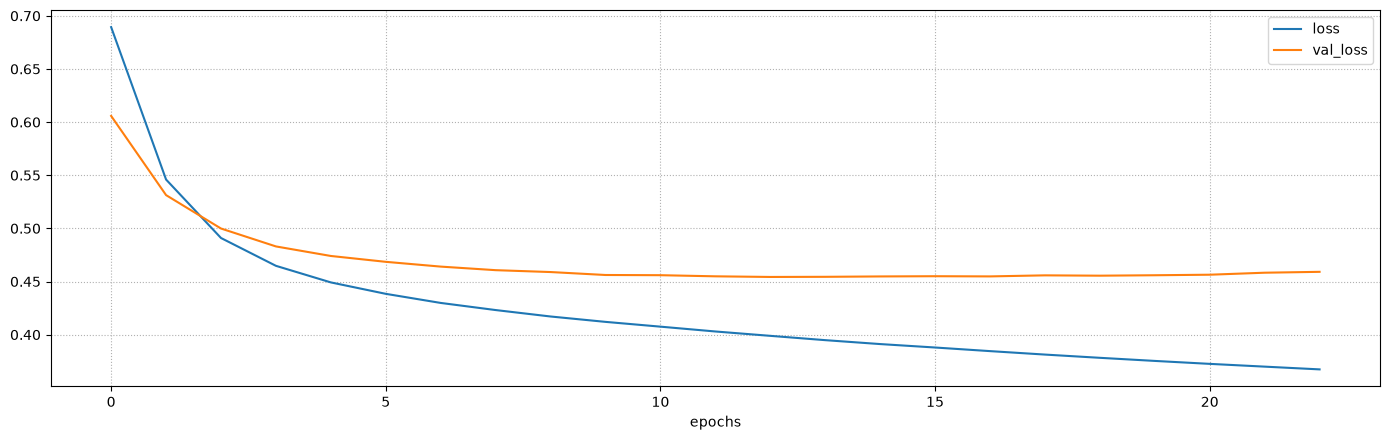

Final loss: 0.3673 (training), 0.4591 (validation)


In [30]:
nn0 = util.build_nn_model(input_shape=(X_tr.shape[1],), output_shape=(y_tr.shape[1],), hidden=[32], output_activation='sigmoid', name='baseline')
history = util.train_nn_model(nn0, X_tr, y_tr, epochs=200, validation_split=0.1, loss='binary_crossentropy')
util.plot_training_history(history, figsize=figsize)

## Accuracy Evaluation

**We can evaluated the model in terms of per-class accuracy**

Average class accuracy: 0.804 (test)


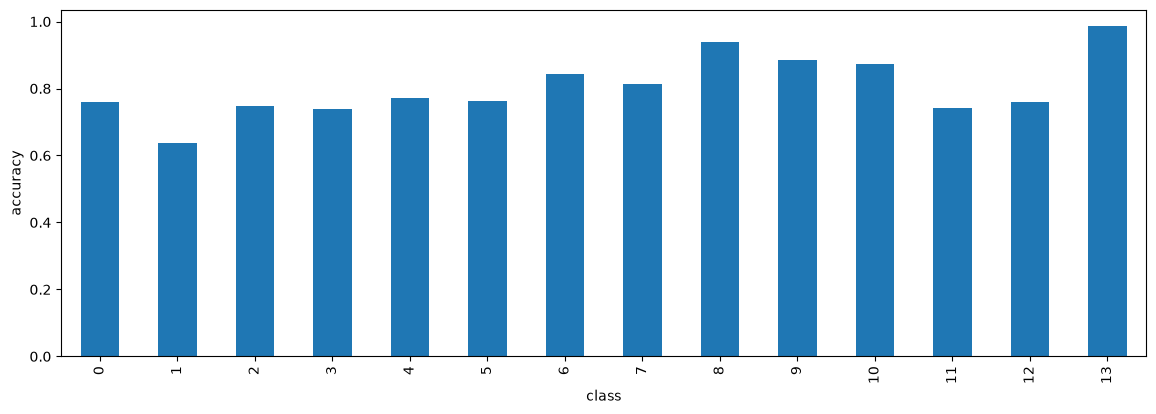

In [44]:
p_ts = nn0.predict(X_ts, verbose=0)
c_ts = np.round(p_ts)
ts_acc = util.get_multi_label_accuracy(y_ts, c_ts, series_name='original')
ts_acc.plot.bar(figsize=figsize, xlabel='class', ylabel='accuracy');
print(f'Average class accuracy: {ts_acc.mean():.3f} (test)')

## Mutually Exclusive Classes

**We will assume that certaint traits cannot occur together**

...Meaning that certain classes are mutually exclusive

* In this case, the constraint is just a purely synthetic example
* In the real world, contraints may come from regulation, domain knowledge, etc.

**We will treat as mutually exclusive all pairs of classes**

...That have a low-enough rate of co-occurrence _in the entire dataset_

In [54]:
all_y = pd.concat((y_tr, y_ts))
forbidden = util.get_forbidden_pairs(all_y, cutoff_quantile=0.65)
print(forbidden)

{(4, 9), (3, 7), (4, 6), (12, 13), (3, 10), (5, 13), (3, 13), (0, 2), (5, 10), (8, 9), (0, 5), (8, 12), (1, 6), (0, 8), (2, 5), (1, 9), (2, 8), (7, 10), (6, 8), (7, 13), (3, 9), (4, 8), (3, 6), (5, 9), (8, 11), (0, 7), (2, 4), (0, 4), (0, 10), (2, 7), (9, 13), (0, 13), (2, 10), (1, 8), (11, 13), (2, 13), (7, 9), (6, 13), (6, 10), (4, 7), (3, 5), (4, 10), (3, 8), (4, 13), (5, 8), (0, 3), (0, 9), (8, 10), (1, 4), (0, 6), (8, 13), (2, 9), (1, 7), (1, 13), (2, 6), (10, 13), (1, 10), (6, 9), (7, 8)}


## Checking Violations

**We can check how often our constraints are violated on the test data**

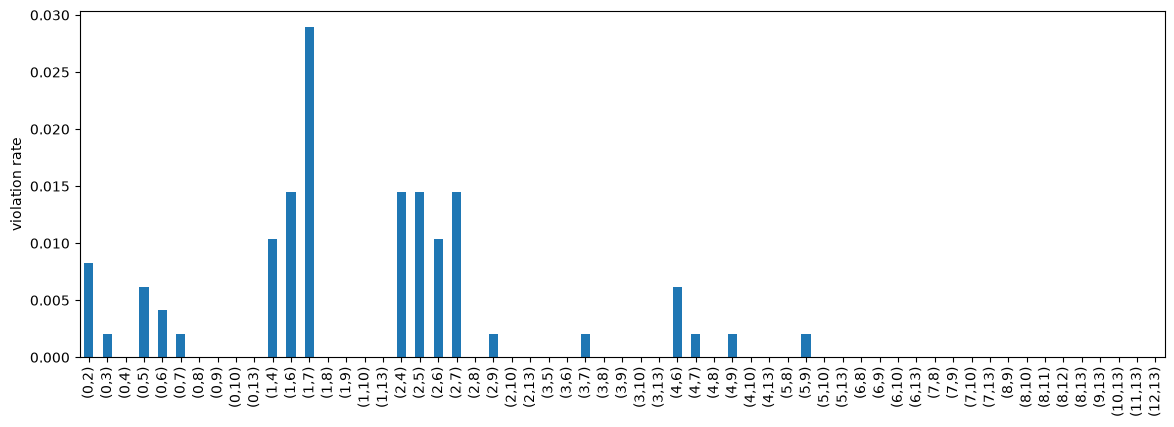

In [56]:
util.forbidden_pair_violation(c_ts, forbidden).plot.bar(figsize=figsize, ylabel='violation rate');

There are some violations, though not many

## Projection Model

**We now need to define out projection problem:**

$$
\hat{z}(x) \in \mathop{\rm arg\,min}_{z} \{ L(z, \hat{y}) \mid g(x, z) \leq 0 \} \quad \text{ with: } \hat{y} = f(x; \theta^*)
$$

For _pre-computed $\hat{y}$_, we'll need to obtain a declarative model of:

* The decision variables $z$
* The loss function $L(z, \hat{y})$
* The constraints $g(x, z) \leq 0$

**The decision variables represent a _vector of classes_**

$$
z_i \in \{0, 1\} \quad \text{ with } z_i = 1 \text{ iff we predict class $i$}
$$

## Projection Model

**We'l use the binary cross entropy as our loss function**

* The decision variables represent _actual classes_
* ...While the $\hat{y}$ contains estimated probabilities

**Hence, we can model the loss function as:**

$$
L(z, \hat{y}) = - \sum_{i=1}^k z_i \log (\hat{y}_i + \varepsilon) + (1 - z_i) \log (1 - \hat{y}_i + \varepsilon)
$$

* Since the cross-entropy is not well defined for $\hat{y}$ equal to 0 or 1
* ...We add a small constant to the logarithm

Overall, we have a _linear expression_ defined on $z$

## Projection Model

**The constraints state that certaint pairs of classes cannot occur together**

...Which can be modeled as:

$$
z_i + z_j \leq 1 \quad \forall (i, j) \in F
$$

* We consider all pairs of mutually exclusive classes
* ...And we allow at most one of the associated $z$ variables to be 1

**Overall, we have the following Integer Linear Program**

$$\begin{align}
\mathop{\rm arg\,min}_{z}\ & z^T \log (\hat{y} + \varepsilon) + (1-z)^T \log (1-\hat{y} + \varepsilon) \\
\text{subject to: } & z_i + z_j \leq 1 & \forall (j, j) \in F \\
& z_i \in \{0, 1\} & \forall i = 1..n_c
\end{align}$$

## Maximum Weight Indedendent Set

**What we are looking for is a [maximum weight independent set](https://en.wikipedia.org/wiki/Independent_set_(graph_theory))**

...On the graph defined by the mutually exclusive classes

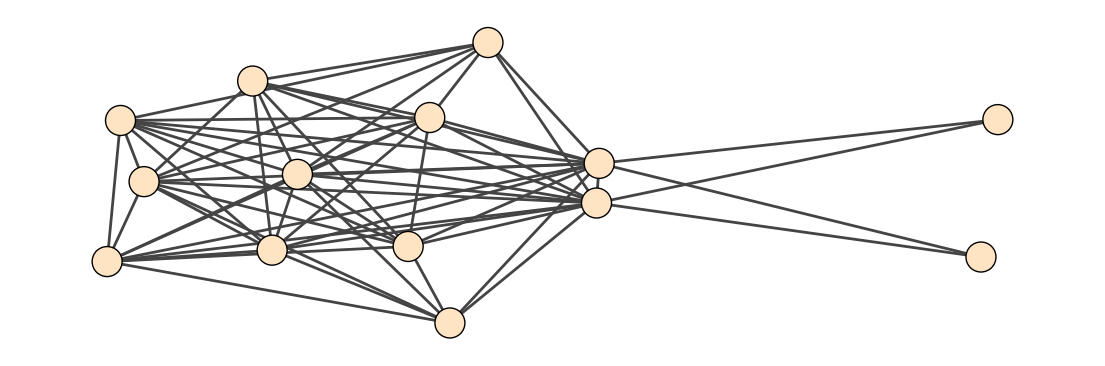

In [57]:
util.plot_forbidden_pairs(nclasses=y_tr.shape[1], forbidden=forbidden, figsize=figsize)

* This is an NP-hard problem, but _not a very difficult one_!

## Implementation

**An implementation of the model is available in the `util` module**

```python
def project_multilabel_classification(p, forbidden, solver='CBC', tlim=10):
    ...
    z = [slv.IntVar(0, 1, 'z_{c}') for c in range(label_num)]
    for c0, c1 in forbidden: # constraintes
        slv.Add(z[c0] + z[c1] <= 1)
    for ii in range(p.shape[0]):
        # Define the objective
        obj = - sum([z[c] * np.log(p[ii, c] + 1e-4) +
                     (1 - z[c])*np.log(1 - p[ii, c] + 1e-4)
                     for c in range(label_num)])
        slv.Minimize(obj)
        status = slv.Solve()
        ...
```

* For improved efficiency, we build _a single model_ to project multiple examples
* On each example, we just change the objective function

## Computing the Projections

**We can now compute the inference-time projections for the test set**

In [58]:
%time pc_ts = util.project_multilabel_classification(p_ts, forbidden=forbidden, tlim=10, solver='SCIP')
print(f'For {len(p_ts)} test examples')

CPU times: user 185 ms, sys: 62.1 ms, total: 247 ms
Wall time: 246 ms
For 484 test examples


* Even if the problem is technically intractable (NP-hard)
* ...The run time is _very low_!

**For roughly 10% of the example the projection results in a change:**

In [59]:
nc_ts = np.any(np.abs(pc_ts - c_ts) > 0, axis=1).sum()
print(f'Non-trivial projections: {nc_ts} (test)')

Non-trivial projections: 43 (test)


## Accuracy Evaluation

**We can compare the accuracy of the constrained model with the original one**

Average class accuracy: 0.805 (projected), 0.804 (original)


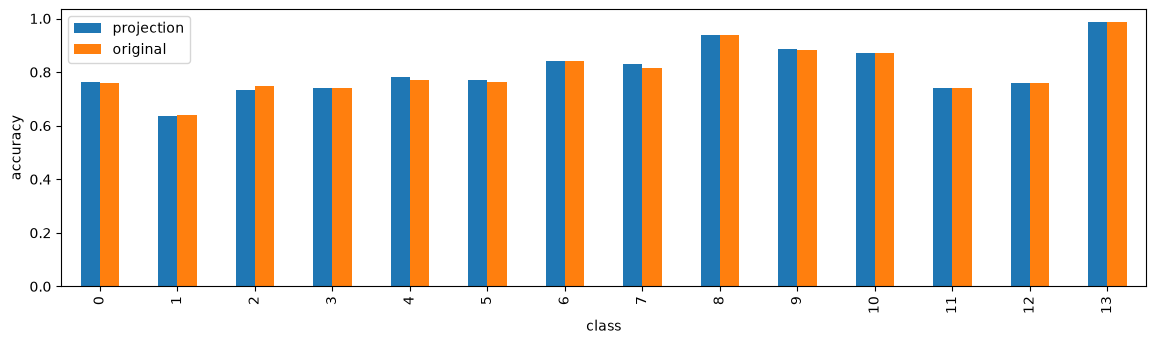

In [60]:
ts_acc_p = util.get_multi_label_accuracy(y_ts, pc_ts, series_name='projection')
tmp = pd.concat([ts_acc_p, ts_acc], axis=1)
tmp.plot.bar(figsize=(figsize[0], figsize[1]*0.8), xlabel='class', ylabel='accuracy');
print(f'Average class accuracy: {ts_acc_p.mean():.3f} (projected), {ts_acc.mean():.3f} (original)')

* In some cases, the constrained model works even better!
* This happens since the constraints encode some _information about unseen examples_

## Accuracy Evaluation

**Projection methods enable also a comparison _against an oracle_**

Which can be obtained by _projecting the ground truth labels_

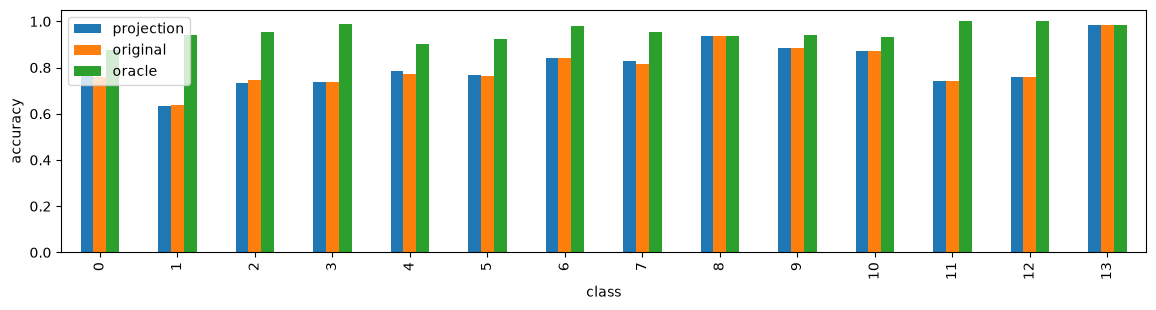

In [61]:
oc_ts = pc_ts = util.project_multilabel_classification(y_ts.values, forbidden=forbidden, tlim=10, solver='SCIP')
ts_acc_o = util.get_multi_label_accuracy(y_ts, oc_ts, series_name='oracle')
tmp = pd.concat([ts_acc_p, ts_acc, ts_acc_o], axis=1)
tmp.plot.bar(figsize=(figsize[0], figsize[1]*0.7), xlabel='class', ylabel='accuracy');

Doing this tells us _the best we could do_, accounting for the constraints

## Training Data Projection

**Projection can be applied _before training_, too**

* We simply use optimization to change the _training labels_
* ...Then we train a model as usual

**In this setting, we naturally have access to batches of examples**

* We can easily account for relational and distributional constraints
* ...At the cost of a higher computational complexity

**The guarantees are weaker**

* In this settting, generalization depends entirely on the trained model
* ...Hence we have no out-of-distribution guarantees